<a href="https://colab.research.google.com/github/Accord985/Hist2ST/blob/main/notebooks/HEST_Patient_Level_Split_EN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HEST Data Preparation (Patient-Level Split) | Google Colab

Filter HEST metadata, split by Sample ID, download paired image/expression files, export PNG and CSV, and validate the results in one notebook. **Preview mode by default:** one sample per split and up to 100 patches per sample.

## 0. Install dependencies

In [1]:
%pip -q install pandas numpy scikit-learn huggingface_hub h5py anndata pillow scipy matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.


## 1. Configuration

Adjust filters as needed. `TECHNOLOGY_FILTER` must match a category in the metadata exactly; use `None` to include all technologies.

In [2]:
from pathlib import Path
import re, json, shutil
import numpy as np
import pandas as pd
import h5py
import anndata as ad
from PIL import Image
from scipy import sparse
from sklearn.model_selection import train_test_split
from huggingface_hub import snapshot_download
from IPython.display import display

# ===== Editable settings =====
METADATA_CSV = Path('/content/HEST_v1_3_0.csv')
OUT = Path('/content/project_data')
SPECIES_FILTER = ['Homo sapiens']
ORGAN_FILTER = ['Breast']
TECHNOLOGY_FILTER = ['Spatial Transcriptomics']
TRAIN_SIZE = 0.7
SEED = 42
DOWNLOAD = True
EXPORT_PNG = True
MAX_PATCHES_PER_SAMPLE = 100  # Preview first; set to None for full export
# Optional: limit downloaded samples in the preview; set None for all.
MAX_SAMPLES_PER_SPLIT = 1

OUT.mkdir(parents=True, exist_ok=True)
print('Output:', OUT)

Output: /content/project_data


## 2. Prepare metadata

Upload `HEST_v1_3_0.csv`, or place it in `/content/` before running.

In [3]:
from google.colab import files
if not METADATA_CSV.exists():
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError('Please upload HEST_v1_3_0.csv or update METADATA_CSV.')
    METADATA_CSV = Path('/content') / next(iter(uploaded))
print('Using metadata:', METADATA_CSV)
print(pd.read_csv(METADATA_CSV, nrows=3).columns.tolist())

Saving HEST_v1_3_0.csv to HEST_v1_3_0.csv
Using metadata: /content/HEST_v1_3_0.csv
['dataset_title', 'id', 'image_filename', 'organ', 'disease_state', 'oncotree_code', 'species', 'patient', 'st_technology', 'data_publication_date', 'license', 'study_link', 'download_page_link1', 'inter_spot_dist', 'spot_diameter', 'spots_under_tissue', 'preservation_method', 'nb_genes', 'treatment_comment', 'pixel_size_um_embedded', 'pixel_size_um_estimated', 'magnification', 'fullres_px_width', 'fullres_px_height', 'tissue', 'disease_comment', 'subseries', 'hest_version_added']


## 3. Filter samples (Stage 1)

Select Sample IDs by species, organ, and ST technology. The full filtered table is saved to `metadata/filtered_metadata.csv`.

In [4]:
def apply_filter(df: pd.DataFrame, column: str, choices):
    if choices is None:
        return df
    if column not in df:
        raise KeyError(f'Missing metadata column: {column}')
    return df[df[column].isin(choices)]

def filter_metadata() -> pd.DataFrame:
    if not METADATA_CSV.exists():
        raise FileNotFoundError(f'No metadata at {METADATA_CSV}. Download HEST_v1_3_0.csv first.')
    meta = pd.read_csv(METADATA_CSV)
    required = {'id', 'species', 'organ', 'st_technology'}
    missing = required - set(meta.columns)
    if missing:
        raise KeyError(f'Missing columns: {sorted(missing)}')
    print('Available st_technology values:\n', meta['st_technology'].value_counts(dropna=False))
    filtered = apply_filter(meta, 'species', SPECIES_FILTER)
    filtered = apply_filter(filtered, 'organ', ORGAN_FILTER)
    filtered = apply_filter(filtered, 'st_technology', TECHNOLOGY_FILTER)
    filtered = filtered.dropna(subset=['id']).copy()
    filtered['id'] = filtered['id'].astype(str).str.strip()
    filtered = filtered.drop_duplicates(subset=['id']).sort_values('id').reset_index(drop=True)
    print(f'Rows: {len(meta)} -> unique samples: {len(filtered)}')
    if filtered.empty:
        raise ValueError('No matching samples. Review filter values printed above.')
    (OUT / 'metadata').mkdir(parents=True, exist_ok=True)
    filtered.to_csv(OUT / 'metadata' / 'filtered_metadata.csv', index=False)
    print('First 20 selected IDs:', filtered['id'].head(20).tolist())
    return filtered

filtered = filter_metadata()
display(filtered.head())

Available st_technology values:
 st_technology
Visium                     602
Spatial Transcriptomics    552
Xenium                      79
Visium HD                   28
Visium HD 3'                 8
Xenium 5k                    7
Name: count, dtype: int64
Rows: 1276 -> unique samples: 108
First 20 selected IDs: ['SPA0', 'SPA1', 'SPA100', 'SPA101', 'SPA102', 'SPA103', 'SPA104', 'SPA105', 'SPA106', 'SPA107', 'SPA108', 'SPA109', 'SPA110', 'SPA111', 'SPA112', 'SPA113', 'SPA114', 'SPA115', 'SPA116', 'SPA117']


,dataset_title,id,image_filename,organ,disease_state,oncotree_code,species,patient,st_technology,data_publication_date,...,treatment_comment,pixel_size_um_embedded,pixel_size_um_estimated,magnification,fullres_px_width,fullres_px_height,tissue,disease_comment,subseries,hest_version_added
0,Visualization and analysis of gene expression ...,SPA0,SPA0.tif,Breast,Cancer,IDC,Homo sapiens,NaN,Spatial Transcriptomics,1-Jul-16,...,NaN,NaN,0.687102,20x,9261,9933,Breast,NaN,Breast Cancer Layer 4,v1_0_0
1,Visualization and analysis of gene expression ...,SPA1,SPA1.tif,Breast,Cancer,IDC,Homo sapiens,NaN,Spatial Transcriptomics,1-Jul-16,...,NaN,NaN,0.684543,20x,9277,9931,Breast,NaN,Breast Cancer Layer 3,v1_0_0
2,Integrating spatial gene expression and breast...,SPA100,SPA100.tif,Breast,Cancer,IDC,Homo sapiens,BC23810,Spatial Transcriptomics,30-Nov-21,...,NaN,NaN,0.697062,20x,9322,9906,Breast,HER2_non_luminal,BC23810_E1,v1_0_0
3,Integrating spatial gene expression and breast...,SPA101,SPA101.tif,Breast,Cancer,IDC,Homo sapiens,BC23810,Spatial Transcriptomics,30-Nov-21,...,NaN,NaN,0.702078,20x,9307,9855,Breast,HER2_non_luminal,BC23810_D2,v1_0_0
4,Integrating spatial gene expression and breast...,SPA102,SPA102.tif,Breast,Cancer,IDC,Homo sapiens,BC23567,Spatial Transcriptomics,30-Nov-21,...,NaN,NaN,0.684350,20x,9344,9907,Breast,HER2_non_luminal,BC23567_E2,v1_0_0


## 4. Split by Sample ID, 70/30 (Stage 2)

Each Sample ID belongs to either train or test. **This does not automatically guarantee patient-level independence across multiple samples.**

In [5]:
def split_metadata(filtered: pd.DataFrame):
    if len(filtered) < 2:
        raise ValueError('Need at least two Sample IDs for train/test splitting.')
    train_ids, test_ids = train_test_split(
        filtered['id'].tolist(), train_size=TRAIN_SIZE, random_state=SEED, shuffle=True
    )
    train_df = filtered[filtered['id'].isin(train_ids)].copy().sort_values('id')
    test_df = filtered[filtered['id'].isin(test_ids)].copy().sort_values('id')
    assert set(train_df['id']).isdisjoint(test_df['id'])
    for split, df in [('train', train_df), ('test', test_df)]:
        df.to_csv(OUT / 'metadata' / f'{split}_samples.csv', index=False)
        (OUT / split).mkdir(parents=True, exist_ok=True)
    print(f'Train: {len(train_df)} samples; test: {len(test_df)} samples')
    return train_df, test_df

train_df, test_df = split_metadata(filtered)
display(train_df[["id"]].head())
display(test_df[["id"]].head())

Train: 75 samples; test: 33 samples


,id
1,SPA1
2,SPA100
3,SPA101
5,SPA103
6,SPA104


,id
0,SPA0
4,SPA102
9,SPA107
10,SPA108
11,SPA109


## 5. Hugging Face authentication

Accept the HEST dataset terms on Hugging Face first, then enter your token through the Colab login prompt. Never hard-code tokens.

In [6]:
from huggingface_hub import notebook_login
notebook_login()

## 6. Download, match, and export (Stage 3)

Download only `patches/{id}.h5` and `st/{id}.h5ad`. Match on normalized barcodes; never rely on row positions. Handles the serialized NCBI barcode format `"[b'000x002']"`.

In [7]:
def fetch_sample(sample_id: str, download_root: Path):
    # Explicit filenames avoid downloading giant whole-slide TIFF images.
    if not re.fullmatch(r'[A-Za-z0-9_-]+', sample_id):
        raise ValueError(f'Unsafe Sample ID: {sample_id!r}')
    expected = [download_root / 'patches' / f'{sample_id}.h5',
                download_root / 'st' / f'{sample_id}.h5ad']
    if all(p.exists() for p in expected):
        return expected
    if not DOWNLOAD:
        raise FileNotFoundError(f'Missing files for {sample_id}: {expected}')
    snapshot_download(
        repo_id='MahmoodLab/hest', repo_type='dataset',
        local_dir=str(download_root),
        allow_patterns=[f'patches/{sample_id}.h5', f'st/{sample_id}.h5ad'],
    )
    for p in expected:
        if not p.exists():
            raise FileNotFoundError(f'Not present on HF or download failed: {p}')
    return expected

def normalize_barcode(value):
    """Normalize HEST patch barcodes, including serialized bytes-list strings.

    Examples:
        b'000x002'         -> 000x002
        '"[b\\'000x002\\']"' -> 000x002
    Never change the meaning of a spot ID by stripping prefixes/suffixes.
    """
    import ast
    import re

    if isinstance(value, (bytes, np.bytes_)):
        value = value.decode('utf-8')
    value = str(value).strip()

    # A few HEST datasets serialize an array of one byte string as text,
    # sometimes enclosed in another layer of quotes.
    for _ in range(3):
        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError, TypeError):
            break
        if isinstance(parsed, (list, tuple)) and len(parsed) == 1:
            value = parsed[0]
        elif isinstance(parsed, (bytes, np.bytes_)):
            value = parsed.decode('utf-8')
        elif isinstance(parsed, str):
            if parsed == value:
                break
            value = parsed
        else:
            break
        if isinstance(value, (bytes, np.bytes_)):
            value = value.decode('utf-8')
        value = str(value).strip()
    return value

def decode_strings(values):
    return [normalize_barcode(v) for v in values]

def save_one_sample(sample_id: str, split: str, raw_root: Path):
    sample_dir = OUT / split / sample_id
    patch_path, st_path = fetch_sample(sample_id, raw_root)
    sample_dir.mkdir(parents=True, exist_ok=True)
    # Explicit keys reported in official HEST patch H5 workflow.
    with h5py.File(patch_path, 'r') as f:
        if 'img' not in f or 'barcode' not in f:
            raise KeyError(f'{patch_path} keys are {list(f.keys())}; expected img and barcode')
        patch_barcodes = decode_strings(f['barcode'][:])
        if len(patch_barcodes) != len(f['img']):
            raise ValueError(f'Barcode/image count mismatch in {sample_id}')
        if len(set(patch_barcodes)) != len(patch_barcodes):
            raise ValueError(f'Duplicate patch barcodes in {sample_id}')
        adata = ad.read_h5ad(st_path)
        if not adata.obs_names.is_unique:
            raise ValueError(f'Duplicate gene-expression barcodes in {sample_id}')
        normalized_obs_names = pd.Index([normalize_barcode(x) for x in adata.obs_names])
        if not normalized_obs_names.is_unique:
            raise ValueError(f'Duplicate normalized gene-expression barcodes in {sample_id}')
        idx = normalized_obs_names.get_indexer(patch_barcodes)
        matched_patch_idx = np.flatnonzero(idx >= 0)
        if MAX_PATCHES_PER_SAMPLE is not None:
            matched_patch_idx = matched_patch_idx[:MAX_PATCHES_PER_SAMPLE]
        print(f'{split}/{sample_id}: {np.count_nonzero(idx >= 0)}/{len(patch_barcodes)} patches matched; exporting {len(matched_patch_idx)}')
        if not len(matched_patch_idx):
            raise ValueError(f'No patch barcodes match AnnData obs_names: {sample_id}')
        selected_barcodes = [patch_barcodes[int(i)] for i in matched_patch_idx]
        row_idx = idx[matched_patch_idx]
        names = [f'spot_{j:06d}.png' for j in range(len(matched_patch_idx))]
        manifest = pd.DataFrame({'filename': names, 'barcode': selected_barcodes, 'patch_index': matched_patch_idx})
        if EXPORT_PNG:
            # Remove obsolete images from earlier preview/full exports.
            image_dir = sample_dir / 'images'
            if image_dir.exists():
                shutil.rmtree(image_dir)
        else:
            # An export without PNGs must not keep old images.
            image_dir = sample_dir / 'images'
            if image_dir.exists():
                shutil.rmtree(image_dir)
        manifest.to_csv(sample_dir / 'patch_manifest.csv', index=False)
        if EXPORT_PNG:
            image_dir = sample_dir / 'images'
            image_dir.mkdir(exist_ok=True)
            for j, i in enumerate(matched_patch_idx):
                image = np.asarray(f['img'][int(i)])
                if image.dtype != np.uint8:
                    raise TypeError(f'Unexpected image dtype {image.dtype} in {sample_id}')
                Image.fromarray(image).save(image_dir / names[j])

    y = adata.X[row_idx]
    if sparse.issparse(y):
        y = y.toarray()
    y = np.asarray(y)
    genes = adata.var_names.astype(str).tolist()
    if len(set(genes)) != len(genes):
        raise ValueError(f'Duplicate gene names in {sample_id}; cannot create CSV columns')
    values = pd.DataFrame(y, columns=genes)
    values.insert(0, 'barcode', selected_barcodes)
    values.insert(0, 'filename', names)
    values.to_csv(sample_dir / 'gene_expression.csv', index=False)
    # Preserve the original h5ad for later normalization and biological analysis.
    (sample_dir / 'source_files.json').write_text(json.dumps({
        'patch_h5': str(patch_path), 'expression_h5ad': str(st_path),
        'n_exported': len(names), 'n_genes': len(genes),
        'expression_values': 'Original adata.X values; NOT normalized by this pipeline'
    }, indent=2))
    return len(names)

In [8]:
# Confirm the known problematic formats before exporting
assert normalize_barcode('"[b\'000x002\']"') == '000x002'
assert normalize_barcode(b'000x003') == '000x003'
assert normalize_barcode('000x004') == '000x004'
print('Barcode normalization self-test passed.')


Barcode normalization self-test passed.


### 6.1 Run export

Preview mode exports one sample per split and up to 100 PNGs each. After validation, set both `MAX_...` parameters to `None` and rerun from the configuration cell.

In [9]:
raw_root = OUT / 'raw_hest'
failures = []
for split, df in [('train', train_df), ('test', test_df)]:
    sample_ids = df['id'].astype(str).tolist()
    if MAX_SAMPLES_PER_SPLIT is not None:
        sample_ids = sample_ids[:MAX_SAMPLES_PER_SPLIT]
    for sample_id in sample_ids:
        try:
            n = save_one_sample(sample_id, split, raw_root)
            print(f'Done: {split}/{sample_id} ({n} paired spots)')
        except Exception as exc:
            print(f'FAILED {split}/{sample_id}: {type(exc).__name__}: {exc}')
            failures.append({'split': split, 'id': sample_id, 'error': str(exc)})
failure_file = OUT / 'metadata' / 'failures.csv'
if failures:
    pd.DataFrame(failures).to_csv(failure_file, index=False)
    print(f'{len(failures)} failed; see metadata/failures.csv')
else:
    if failure_file.exists():
        failure_file.unlink()
    print('Finished selected samples successfully.')

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

train/SPA1: 264/264 patches matched; exporting 100
Done: train/SPA1 (100 paired spots)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

test/SPA0: 262/262 patches matched; exporting 100
Done: test/SPA0 (100 paired spots)
Finished selected samples successfully.


## 7. Inspect paired output

Display a real H&E patch and its eight highest-valued gene expressions at the same barcode. `adata.X` is not necessarily raw counts.

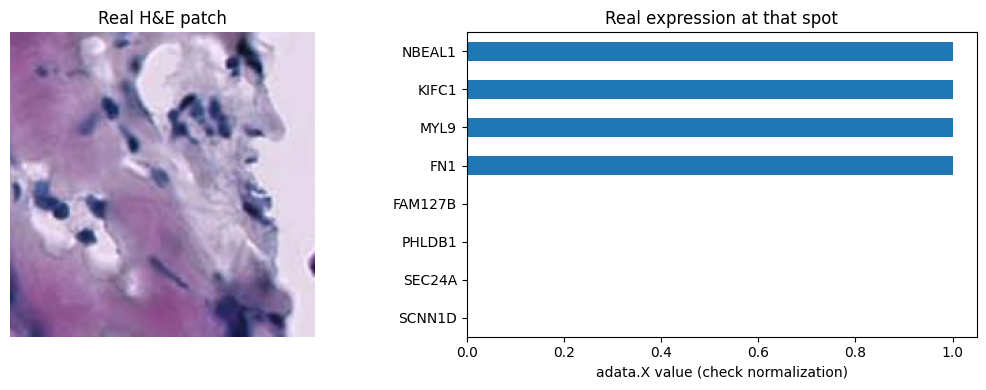

Sample: SPA1 Barcode: 23.19x8.03
CSV: /content/project_data/train/SPA1/gene_expression.csv


In [12]:
import matplotlib.pyplot as plt
examples = list((OUT/'train').glob('*/gene_expression.csv')) + list((OUT/'test').glob('*/gene_expression.csv'))
if not examples:
    print('No exported samples yet. Run Stage 3 and check errors.')
else:
    csv_path = examples[0]
    data = pd.read_csv(csv_path)
    manifest = pd.read_csv(csv_path.parent/'patch_manifest.csv')
    assert (data['barcode'].astype(str).values == manifest['barcode'].astype(str).values).all()
    row = data.iloc[0]
    img_path = csv_path.parent/'images'/str(row['filename'])
    values = row.drop(labels=['filename','barcode']).astype(float).sort_values(ascending=False).head(8)
    fig, axes = plt.subplots(1,2,figsize=(11,4))
    if img_path.exists():
        axes[0].imshow(Image.open(img_path))
        axes[0].set_title('Real H&E patch')
        axes[0].axis('off')
    else:
        axes[0].text(.1,.5, f'PNG not exported: {img_path.name}')
        axes[0].axis('off')
    values.sort_values().plot.barh(ax=axes[1])
    axes[1].set_title('Real expression at that spot')
    axes[1].set_xlabel('adata.X value (check normalization)')
    plt.tight_layout(); plt.show()
    print('Sample:', csv_path.parent.name, 'Barcode:', row['barcode'])
    print('CSV:', csv_path)

## 8. Validate exports

Check sample split, matching PNG/CSV/manifest records, image dimensions, numeric values, and gene-set overlap across exported samples. `NOT_EXPORTED` is expected during preview.

In [13]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

# Same output directory as the Fixed Notebook
root = OUT
metadata_dir = OUT / "metadata"

train_meta = pd.read_csv(metadata_dir / "train_samples.csv", dtype={"id": str})
test_meta = pd.read_csv(metadata_dir / "test_samples.csv", dtype={"id": str})
filtered_meta = pd.read_csv(metadata_dir / "filtered_metadata.csv", dtype={"id": str})

# =============================================
# 1. Check metadata and train/test split
# =============================================
train_ids = set(train_meta["id"])
test_ids = set(test_meta["id"])
filtered_ids = set(filtered_meta["id"])

assert train_ids.isdisjoint(test_ids), "Train/test IDs overlap!"
assert train_ids | test_ids == filtered_ids, "Split does not cover all filtered IDs!"

print("=== METADATA CHECK ===")
print("Filtered samples:", len(filtered_ids))
print("Train IDs:", len(train_ids))
print("Test IDs:", len(test_ids))
print("Overlap:", len(train_ids & test_ids))
print("\nFiltered technologies:")
print(filtered_meta["st_technology"].value_counts())

# =============================================
# 2. Inspect exported sample folders
# =============================================
records = []
gene_sets = {}

for split, expected_ids in [("train", train_ids), ("test", test_ids)]:
    for sample_id in sorted(expected_ids):
        sample_dir = root / split / sample_id
        csv_path = sample_dir / "gene_expression.csv"
        manifest_path = sample_dir / "patch_manifest.csv"
        image_dir = sample_dir / "images"

        record = {
            "split": split,
            "sample_id": sample_id,
            "status": "NOT_EXPORTED",
            "n_csv_rows": 0,
            "n_manifest_rows": 0,
            "n_png_files": 0,
            "n_genes": 0,
            "barcodes_match": False,
            "filenames_match": False,
            "png_dimensions_ok": False,
            "unique_barcodes": False,
            "numeric_values_ok": False,
            "notes": ""
        }

        # A sample may be absent in preview mode
        if not csv_path.exists() or not manifest_path.exists():
            records.append(record)
            continue

        try:
            expression = pd.read_csv(
                csv_path, dtype={"barcode": str, "filename": str}
            )
            manifest = pd.read_csv(
                manifest_path, dtype={"barcode": str, "filename": str}
            )

            png_files = list(image_dir.glob("*.png")) if image_dir.exists() else []
            gene_cols = [
                c for c in expression.columns
                if c not in ["barcode", "filename"]
            ]

            record["n_csv_rows"] = len(expression)
            record["n_manifest_rows"] = len(manifest)
            record["n_png_files"] = len(png_files)
            record["n_genes"] = len(gene_cols)

            # Compare rows in exactly the same order
            record["barcodes_match"] = (
                expression["barcode"].tolist()
                == manifest["barcode"].tolist()
            )
            record["filenames_match"] = (
                expression["filename"].tolist()
                == manifest["filename"].tolist()
            )

            record["unique_barcodes"] = (
                expression["barcode"].is_unique
                and manifest["barcode"].is_unique
            )

            expected_pngs = set(expression["filename"])
            actual_pngs = {p.name for p in png_files}

            file_counts_ok = (
                len(expression) > 0
                and len(expression) == len(manifest) == len(png_files)
                and expected_pngs == actual_pngs
                and expression["filename"].is_unique
                and manifest["filename"].is_unique
            )

            # Check image dimensions and file readability
            dimensions_ok = True
            for img_path in png_files:
                with Image.open(img_path) as img:
                    if img.size != (224, 224) or img.mode != "RGB":
                        dimensions_ok = False
            record["png_dimensions_ok"] = dimensions_ok and bool(png_files)

            # Verify gene expression is numeric and finite
            numeric = expression[gene_cols].apply(
                pd.to_numeric, errors="coerce"
            )
            record["numeric_values_ok"] = (
                len(gene_cols) > 0
                and np.isfinite(numeric.to_numpy()).all()
            )

            gene_sets[(split, sample_id)] = set(gene_cols)

            checks = [
                file_counts_ok,
                record["barcodes_match"],
                record["filenames_match"],
                record["unique_barcodes"],
                record["png_dimensions_ok"],
                record["numeric_values_ok"]
            ]

            record["status"] = "PASS" if all(checks) else "FAIL"

        except Exception as e:
            record["status"] = "ERROR"
            record["notes"] = str(e)

        records.append(record)

report = pd.DataFrame(records)

# =============================================
# 3. Check gene list consistency
# =============================================
print("\n=== EXPORT SUMMARY ===")
print(report.groupby(["split", "status"]).size())

print("\nTotal exported PNGs:", report["n_png_files"].sum())
print("Total gene-expression rows:", report["n_csv_rows"].sum())

if gene_sets:
    common_genes = set.intersection(*gene_sets.values())
    union_genes = set.union(*gene_sets.values())

    print("\n=== GENE CONSISTENCY ===")
    print("Samples with gene sets:", len(gene_sets))
    print("Common genes:", len(common_genes))
    print("Total distinct genes:", len(union_genes))
    print("Identical gene sets:", len(common_genes) == len(union_genes))
else:
    print("\nNo gene data exported.")

# =============================================
# 4. Save full report
# =============================================
report_path = metadata_dir / "validation_report.csv"
report.to_csv(report_path, index=False)

print("\nValidation report:", report_path)
display(report)

print("\nPASS samples:", (report["status"] == "PASS").sum())
print("Unexported samples:", (report["status"] == "NOT_EXPORTED").sum())


=== METADATA CHECK ===
Filtered samples: 108
Train IDs: 75
Test IDs: 33
Overlap: 0

Filtered technologies:
st_technology
Spatial Transcriptomics    108
Name: count, dtype: int64

=== EXPORT SUMMARY ===
split  status      
test   NOT_EXPORTED    32
       PASS             1
train  NOT_EXPORTED    74
       PASS             1
dtype: int64

Total exported PNGs: 200
Total gene-expression rows: 200

=== GENE CONSISTENCY ===
Samples with gene sets: 2
Common genes: 14017
Total distinct genes: 15720
Identical gene sets: False

Validation report: /content/project_data/metadata/validation_report.csv


,split,sample_id,status,n_csv_rows,n_manifest_rows,n_png_files,n_genes,barcodes_match,filenames_match,png_dimensions_ok,unique_barcodes,numeric_values_ok,notes
0,train,SPA1,PASS,100,100,100,14929,True,True,True,True,True,
1,train,SPA100,NOT_EXPORTED,0,0,0,0,False,False,False,False,False,
2,train,SPA101,NOT_EXPORTED,0,0,0,0,False,False,False,False,False,
3,train,SPA103,NOT_EXPORTED,0,0,0,0,False,False,False,False,False,
4,train,SPA104,NOT_EXPORTED,0,0,0,0,False,False,False,False,False,
...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,test,SPA80,NOT_EXPORTED,0,0,0,0,False,False,False,False,False,
104,test,SPA81,NOT_EXPORTED,0,0,0,0,False,False,False,False,False,
105,test,SPA87,NOT_EXPORTED,0,0,0,0,False,False,False,False,False,
106,test,SPA92,NOT_EXPORTED,0,0,0,0,False,False,False,False,False,



PASS samples: 2
Unexported samples: 106


## 9. Full export and backup

For a complete run, set `MAX_PATCHES_PER_SAMPLE = None` and `MAX_SAMPLES_PER_SPLIT = None`. When changing filter conditions, use a new `OUT` folder to avoid mixing previous samples. Colab `/content` is temporary; back up important outputs.

## Important notes

- `PASS` confirms structural consistency, not biological validity of measured expression.
- Gene sets differ across samples; select a consistent target gene list and ordering before training.
- `gene_expression.csv` contains values directly from `adata.X`; this pipeline does not normalize them.
- Check patient-level independence when the same donor contributes multiple samples.
- If `EXPORT_PNG = False`, the PNG-focused validation will flag missing images as `FAIL`.